# Task 3 — Statistical analysis of smartphone use and sleep quality

This notebook reproduces descriptive summaries and visual checks using aggregate values published by Siebers et al. (2024). The rows are table-level summaries, **not participant-level observations**. The notebook does not re-estimate the paper's DSEM model.

## 1. Research question
How are social-media and game-app use before/after bedtime associated with daily sleep quality?

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
SEED = 42
np.random.seed(SEED)
RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')

## 2. Load published aggregate tables

In [2]:
app = pd.read_csv(RAW / 'published_app_usage.csv')
phone = pd.read_csv(RAW / 'published_phone_effects.csv')
effects = pd.read_csv(RAW / 'published_app_effects.csv')
desc = pd.read_csv(RAW / 'published_descriptives.csv')
print('App rows:', len(app), '| Effect rows:', len(effects))
app.head()

App rows: 9 | Effect rows: 9


,app_category,timeframe,mean_minutes,sd_minutes
0,Social media,Daytime,146,129
1,Social media,Pre-bedtime,11,14
2,Social media,Post-bedtime,12,27
3,Game apps,Daytime,62,86
4,Game apps,Pre-bedtime,3,9


## 3. Sample and source notes

In [3]:
meta = pd.read_json(RAW / 'source_metadata.json', typ='series')
print(meta['primary_source'])

{'citation': 'Siebers, T., Beyens, I., Baumgartner, S. E., & Valkenburg, P. M. (2024). Adolescents’ Digital Nightlife: The Comparative Effects of Day- and Nighttime Smartphone Use on Sleep Quality. Communication Research.', 'doi': '10.1177/00936502241276793', 'dataset_doi': '10.21942/uva.26395903.v2', 'sample_n': 155, 'observations_sleep_quality': 1950, 'tracked_app_activities': 745706, 'collection_days': 21, 'age_mean': 14.5, 'age_sd': 0.7000000000000001, 'country': 'Netherlands'}


## 4. Descriptive statistics

In [4]:
desc

,measure,mean,sd,unit,icc,between_person_correlation_with_sleep_quality
0,Daily smartphone use,368.00,178.00,hours/day,NaN,NaN
1,Daytime smartphone use,326.00,157.00,minutes/day,0.49,-0.02
2,Pre-bedtime smartphone use,23.00,19.00,minutes/night,0.30,0.11
3,Post-bedtime smartphone use,29.00,49.00,minutes/night,0.30,-0.11
4,Sleep quality,5.53,1.31,1–7 scale,0.47,NaN


## 5. App-use duration by timeframe

In [5]:
app.pivot(index='app_category', columns='timeframe', values='mean_minutes')

timeframe,Daytime,Post-bedtime,Pre-bedtime
app_category,,,
Game apps,62,4,3
Social media,146,12,11
Video player,128,14,11


## 6. App-use visualization

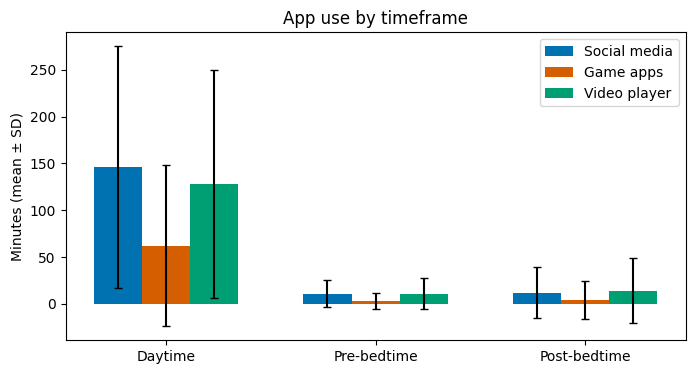

In [6]:
fig, ax = plt.subplots(figsize=(8,4))
frames=['Daytime','Pre-bedtime','Post-bedtime']; x=np.arange(3); w=.23
colors={'Social media':'#0072B2','Game apps':'#D55E00','Video player':'#009E73'}
for i,cat in enumerate(colors):
    g=app[app.app_category==cat].set_index('timeframe').loc[frames]
    ax.bar(x+(i-1)*w,g.mean_minutes,w,yerr=g.sd_minutes,capsize=3,label=cat,color=colors[cat])
ax.set_xticks(x,frames); ax.set_ylabel('Minutes (mean ± SD)'); ax.legend(); ax.set_title('App use by timeframe'); plt.show()

## 7. Overall smartphone-use effects

In [7]:
phone[['timeframe','mean_minutes','sd_minutes','within_person_beta','bayesian_p','ci95_low','ci95_high']]

,timeframe,mean_minutes,sd_minutes,within_person_beta,bayesian_p,ci95_low,ci95_high
0,Daytime,326,157,-0.03,0.122,-0.073,0.022
1,Pre-bedtime,23,19,-0.02,0.162,-0.067,0.025
2,Post-bedtime,29,49,-0.09,0.017,-0.171,-0.006


## 8. App-specific effects

In [8]:
effects.sort_values('within_person_beta')

,app_category,timeframe,within_person_beta,bayesian_p,ci95_low,ci95_high
7,Game apps,Post-bedtime,-0.16,0.024,-0.329,-0.001
3,Social media,Pre-bedtime,-0.09,0.001,-0.144,-0.026
4,Game apps,Pre-bedtime,-0.09,0.050,-0.172,0.015
2,Video player,Daytime,-0.06,0.075,-0.111,0.014
6,Social media,Post-bedtime,-0.05,0.113,-0.153,0.033
1,Game apps,Daytime,-0.02,0.359,-0.134,0.093
8,Video player,Post-bedtime,-0.01,0.451,-0.119,0.079
0,Social media,Daytime,0.00,0.464,-0.059,0.062
5,Video player,Pre-bedtime,0.05,0.070,-0.017,0.100


## 9. Interpretation and limitations

The strongest negative within-person estimate among the app-specific results is game-app use after bedtime (β = −0.16, Bayesian p = .024). Social-media use in the hour before bedtime is also negatively associated with sleep quality (β = −0.09, p = .001). These are observational associations, not proof of causation. The primary study reports a daily 1–7 sleep-quality item, not full PSQI, SOL, TST, WASO or sleep-stage ratios. MMASH is a separate physiological dataset and is not merged with this sample.

## 10. Reproducibility note
All input values are aggregate values transcribed from published Tables 1–4. No artificial participant records or bootstrap intervals are generated.